# Reto 1: Exploración y calidad de datos (EDA)
**Malackathon 2026 · Mercedes-Benz "Clustering the Star"**

**Objetivo de negocio.** Segmentar clientes para personalizar cuatro palancas de marketing:
**ofertas de vehículo**, **planes de mantenimiento**, **campañas de fidelización** y **comunicaciones dirigidas**.
Cada decisión de este notebook se justifica con esa pregunta en mente: *¿esta información ayuda a decidir qué ofrecer, a quién y por qué canal?*

**Regla de explicabilidad.** Cada afirmación del texto lleva detrás un `assert` o una tabla que la demuestra.
Si los datos cambian y una afirmación deja de ser cierta, el notebook falla en lugar de mentir.

Contenido:
1. Carga y granularidad: ¿qué es una fila?
2. Estadísticas descriptivas
3. Calidad: nulos e inconsistencias, con propuesta de tratamiento
4. Columnas excluidas (metadatos, identificadores, redundantes)
5. Vista cliente: ¿cómo son los clientes de Mercedes-Benz?
6. Resumen de hallazgos y conclusiones

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.ticker as mt
from src import config, clean
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
FIG = config.FIG_DIR; FIG.mkdir(parents=True, exist_ok=True)
REF_DATE = pd.Timestamp(config.REF_DATE)  # fecha de referencia común del equipo

# Paleta (skill dataviz): un solo tono para magnitudes, ejes y rejilla recesivos
BLUE, INK, MUTED, GRID = '#2a78d6', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'figure.dpi': 110, 'axes.edgecolor': GRID, 'axes.labelcolor': MUTED, 'xtick.color': MUTED,
    'ytick.color': MUTED, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': .6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.titlecolor': INK, 'font.size': 9})

def barh(s, title, fmt='{:,.0f}', ax=None):
    # Barras horizontales finas con etiqueta directa del valor
    ax = ax or plt.subplots(figsize=(7, .32 * len(s) + .8))[1]
    ax.barh(s.index.astype(str), s.values, color=BLUE, height=.6)
    ax.invert_yaxis(); ax.set_title(title, loc='left'); ax.grid(axis='y', visible=False)
    for i, v in enumerate(s.values): ax.text(v, i, ' ' + fmt.format(v), va='center', color=INK, fontsize=8)
    ax.margins(x=.18); return ax

## 1. Carga y granularidad: ¿qué es una fila?

In [2]:
df = clean.load_raw()  # descarta el índice sin nombre de la exportación y parsea la fecha
n_cli, n_veh = df.client_id.nunique(), df.vehicle_id.nunique()
assert not df.duplicated(['client_id', 'vehicle_id']).any(), 'cada fila debería ser un par cliente-vehículo único'
print(f'{len(df):,} filas = pares cliente-vehículo únicos | {df.shape[1]} columnas | {n_cli:,} clientes | {n_veh:,} vehículos')

302,850 filas = pares cliente-vehículo únicos | 38 columnas | 173,456 clientes | 244,519 vehículos


In [3]:
# ¿Qué atributos son del CLIENTE (constantes en todas sus filas), del VEHÍCULO o de la RELACIÓN?
def pct_varying(key, cols):
    g = df.groupby(key)
    return pd.Series({c: (g[c].nunique(dropna=False) > 1).mean() * 100 for c in cols}).round(2)

client_cols = ['age_range', 'gender_derived', 'months_as_mb_customer', 'currently_connected_vehicles', 'finance_leasing_status',
               'consent_phone_communication_channel', 'consent_epost_communication_channel', 'consent_post_communication_channel',
               'country_code', 'zipcode', 'purchasing_power_per_inhabitant_eur']
vehicle_cols = ['model_series', 'vehicle_type', 'model_class', 'product_group', 'engine_concept', 'fuel_type', 'date_of_first_registration']
rel_cols = ['role', 'is_current_vehicle', 'workshop_visits_warranty_goodwill', 'trip_distance_average', 'operating_hours_total']
vc, vv, vr = pct_varying('client_id', client_cols), pct_varying('vehicle_id', vehicle_cols), pct_varying('vehicle_id', rel_cols)
assert (vc == 0).all() and (vv == 0).all() and (vr > 0).all()
display(vc.to_frame('% clientes con >1 valor'))
display(pd.concat([vv, vr]).to_frame('% vehículos con >1 valor'))

,% clientes con >1 valor
age_range,0.0
gender_derived,0.0
months_as_mb_customer,0.0
currently_connected_vehicles,0.0
finance_leasing_status,0.0
consent_phone_communication_channel,0.0
consent_epost_communication_channel,0.0
consent_post_communication_channel,0.0
country_code,0.0
zipcode,0.0


,% vehículos con >1 valor
model_series,0.00
vehicle_type,0.00
model_class,0.00
product_group,0.00
engine_concept,0.00
fuel_type,0.00
date_of_first_registration,0.00
role,6.85
is_current_vehicle,12.09
workshop_visits_warranty_goodwill,11.98


**Lectura.** El dataset mezcla tres niveles de información:
- **Cliente:** demografía, antigüedad, consentimientos, leasing y zona. Son 100 % constantes por `client_id`, así que se pueden agregar sin perder información.
- **Vehículo:** modelo, clase, motor y fecha de matriculación. Son 100 % constantes por `vehicle_id`.
- **Relación cliente-vehículo:** rol, si está activo, visitas al taller y telemática. Cambian cuando varias personas comparten un coche, por ejemplo propietario y conductor.

**Implicación para marketing:** el cliente es la unidad sobre la que se actúa (a quien se envía la oferta). Proponemos **segmentar a nivel cliente** y resumir sus vehículos con agregados como nº de coches, gama o electrificación.

In [4]:
rows_per_client = df.groupby('client_id').size()
buckets = pd.cut(rows_per_client, [0, 1, 2, 5, 19, np.inf], labels=['1', '2', '3-5', '6-19', '≥20'])
t = pd.DataFrame({'clientes': buckets.value_counts().sort_index(),
                  'filas': rows_per_client.groupby(buckets, observed=False).sum()})
t['% clientes'] = (t.clientes / t.clientes.sum() * 100).round(2); t['% filas'] = (t.filas / t.filas.sum() * 100).round(2)
display(t)
heavy = rows_per_client[rows_per_client >= 20]
print(f'{len(heavy)} clientes ({len(heavy)/n_cli:.2%}) acumulan {heavy.sum():,} filas ({heavy.sum()/len(df):.1%}). Máximo: {rows_per_client.max()} vehículos.')
rt = df[df.client_id.isin(heavy.index)].role_type.value_counts(normalize=True).mul(100).round(1)
print('role_type de sus filas (%):', rt.to_dict())

,clientes,filas,% clientes,% filas
1,127081,127081,73.26,41.96
2,31271,62542,18.03,20.65
3-5,11703,40272,6.75,13.30
6-19,2493,23778,1.44,7.85
≥20,908,49177,0.52,16.24


908 clientes (0.52%) acumulan 49,177 filas (16.2%). Máximo: 561 vehículos.
role_type de sus filas (%): {'B2C': 92.5, 'B2B': 7.5}


**Hallazgo: cuentas de gran volumen.** Un 0,5 % de los clientes concentra el ~16 % de las filas. Tienen entre 20 y 561 vehículos históricos y figuran **mayoritariamente como B2C** (ver % de `role_type` arriba), aunque su volumen corresponde a flotas, renting o concesionarios.
Si no se tratan, **dominan cualquier estadística a nivel fila** y distorsionan el clustering.
Propuesta: marcarlas con un flag (`is_heavy_account`) y analizarlas como un segmento propio: gestión de flotas, key accounts, otro canal comercial.

## 2. Estadísticas descriptivas

In [5]:
num = df.select_dtypes('number')
display(num.describe(percentiles=[.01, .5, .99]).T.round(2))

,count,mean,std,min,1%,50%,99%,max
model_series,302850.0,267.88,150.21,107.00,117.00,243.00,907.00,9.100000e+02
months_as_mb_customer,302846.0,43.87,26.89,0.00,0.00,39.00,115.00,1.200000e+02
currently_connected_vehicles,302850.0,2.15,3.53,0.00,0.00,1.00,19.00,2.100000e+01
workshop_visits_warranty_goodwill,302850.0,1.75,2.43,0.00,0.00,1.00,10.00,4.400000e+01
purchasing_power_per_inhabitant_eur,283763.0,46481.17,17294.53,19701.53,24291.65,46165.64,106183.57,1.483537e+05
purchasing_power_per_household_eur,283763.0,104766.27,41597.55,45087.34,51698.89,102246.51,246174.02,3.424980e+05
population,283836.0,19664.85,36803.22,0.00,470.00,7132.00,220313.00,2.207940e+05
trip_distance_average,116993.0,16.16,10.67,1.00,2.84,14.02,49.39,3.000000e+02
trip_distance_median,123020.0,6.62,7.77,1.00,1.00,7.50,27.50,3.000000e+02
trip_distance_all_counter,123020.0,2351.70,2768.20,0.00,0.00,1593.00,11404.62,8.907800e+04


In [6]:
cat_cols = ['age_range', 'gender_derived', 'country_code', 'product_group', 'engine_concept', 'fuel_type', 'role', 'role_type',
            'finance_leasing_status', 'is_current_vehicle', 'consent_phone_communication_channel',
            'consent_epost_communication_channel', 'consent_post_communication_channel']
display(pd.DataFrame({c: [df[c].nunique(), df[c].mode()[0], round(df[c].value_counts(normalize=True).iloc[0] * 100, 1),
                          round(df[c].isna().mean() * 100, 1)] for c in cat_cols},
                     index=['n_categorías', 'moda', '% moda (sin nulos)', '% nulos']).T)

,n_categorías,moda,% moda (sin nulos),% nulos
age_range,6,45-54,22.5,0.0
gender_derived,2,male,83.0,11.2
country_code,2,CH,63.7,0.0
product_group,4,P,84.4,0.0
engine_concept,4,COMBUSTION,58.4,44.4
fuel_type,7,DIESEL,28.9,59.0
role,5,OWNER,87.3,0.0
role_type,2,B2C,98.2,0.0
finance_leasing_status,4,never_active,58.3,0.0
is_current_vehicle,2,True,59.5,0.0


## 3. Calidad de datos: nulos e inconsistencias

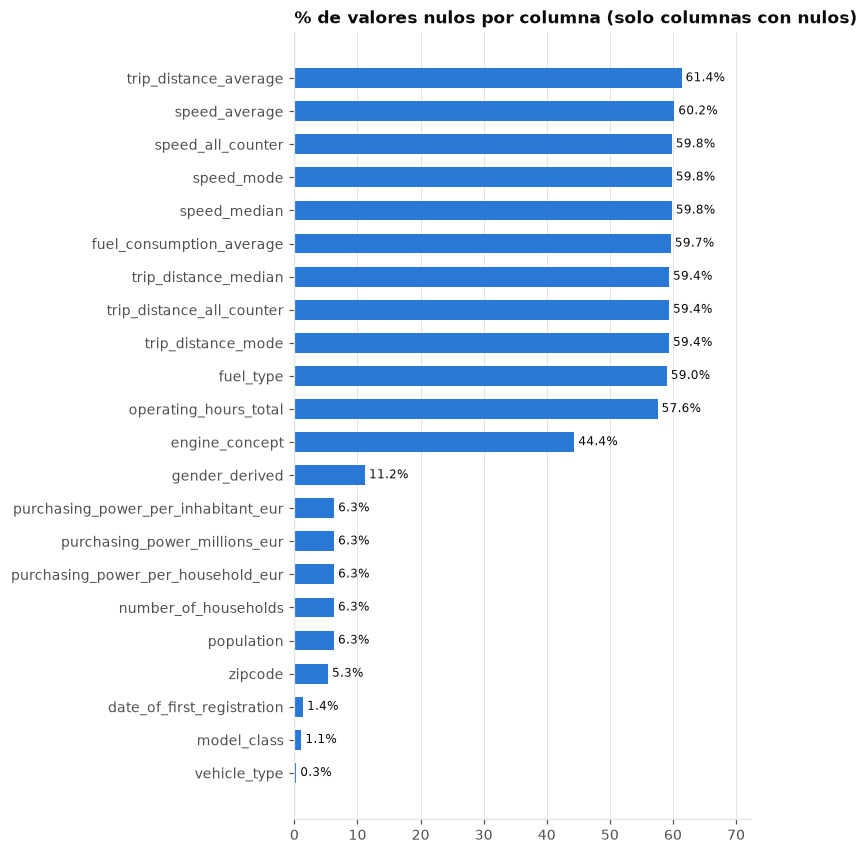

In [7]:
nulls = df.isna().mean().mul(100).round(2)
nulls = nulls[nulls > 0].sort_values(ascending=False)
barh(nulls, '% de valores nulos por columna (solo columnas con nulos)', fmt='{:.1f}%')
plt.tight_layout(); plt.savefig(FIG / '01_nulos.png'); plt.show()

Los nulos forman **cuatro bloques**, cada uno con una causa distinta. Se verifican uno a uno a continuación.

### 3.1 Telemática (~57-61 % nulos): ausencia estructural, no un error

In [8]:
df['has_telemetry'] = df.trip_distance_all_counter.notna()
display(df.groupby('role').has_telemetry.mean().mul(100).round(1).to_frame('% filas con telemática'))
display(df.groupby('is_current_vehicle').has_telemetry.mean().mul(100).round(1).to_frame('% filas con telemática'))
assert df.loc[df.engine_concept.eq('ELECTRIC'), 'fuel_consumption_average'].isna().all()  # un eléctrico no consume combustible
print(f'Clientes con telemática en al menos un vehículo: {df.groupby("client_id").has_telemetry.any().mean():.1%}')

,% filas con telemática
role,
DRIVER,9.9
LEGACY,2.4
OWNER,42.8
TEMP_USER,3.2
USER,50.0


,% filas con telemática
is_current_vehicle,
False,27.1
True,49.8


Clientes con telemática en al menos un vehículo: 52.3%


- La telemática existe sobre todo cuando el cliente es **OWNER/USER** de un coche **conectado**. Para DRIVER, LEGACY y TEMP_USER apenas hay datos (2-10 %).
- `fuel_consumption_average` está vacío en el 100 % de los eléctricos, lo cual es correcto: es un nulo **lógico**.
- Solo la mitad de los clientes tiene telemática. **Imputarla inventaría el comportamiento de conducción de la otra mitad de la base.**

**Tratamiento (decisión D3 del PLAN):**
- Flag `has_telemetry`, que en sí mismo es una señal de cliente conectado o digital.
- Ablación A/B/C en el Reto 3. La evidencia del EDA apunta a **A (sin telemetría) como modelo base**: imputar la mediana a la mitad de la base crea un bloque central artificial.
- La telemática se reserva para perfilar a los clientes que la tienen, por ejemplo con planes de mantenimiento según km u horas de uso.

### 3.2 Motorización (`engine_concept` 44 %, `fuel_type` 59 %): recuperable en parte

In [9]:
display(pd.crosstab(df.engine_concept.fillna('NULO'), df.fuel_type.fillna('NULO')))
assert (df.engine_concept.isna() <= df.fuel_type.isna()).all()  # si falta el motor, falta también el combustible
# El modelo comercial determina el motor: aprender vehicle_type -> engine_concept de las filas conocidas
known = df[df.engine_concept.notna()]
purity = known.groupby('vehicle_type').engine_concept.agg(lambda s: s.value_counts(normalize=True).iloc[0])
mapping = known.groupby('vehicle_type').engine_concept.agg(lambda s: s.mode()[0])
recovered = df.loc[df.engine_concept.isna(), 'vehicle_type'].map(mapping).notna()
print(f'Pureza media vehicle_type -> motor: {purity.mean():.1%} ({(purity == 1).mean():.1%} de los tipos son 100 % puros)')
print(f'Nulos de motor recuperables por mapeo: {recovered.mean():.1%} ({recovered.sum():,} filas)')

fuel_type,DIESEL,"DIESEL,ELECTRIC",ELECTRIC,NULO,PETROL,"PETROL,ELECTRIC",PETROL_PLUS,"PETROL_PLUS,ELECTRIC"
engine_concept,,,,,,,,
COMBUSTION,28475,0,0,43915,14422,0,11612,0
ELECTRIC,0,0,20944,0,0,0,0,0
MILD_HYBRID,7418,0,0,29,17946,0,2362,0
NULO,0,0,0,134390,0,0,0,0
PLUGIN_HYBRID,0,8604,0,411,0,7371,0,4951


Pureza media vehicle_type -> motor: 98.9% (94.7% de los tipos son 100 % puros)
Nulos de motor recuperables por mapeo: 53.7% (72,224 filas)


- `fuel_type` no aporta nada que `engine_concept` no tenga: cuando falta el motor falta también el combustible. Además, `fuel_type` está más vacío.
- Cada `vehicle_type` (p. ej. "GLC 220 d 4MATIC") tiene casi siempre el mismo motor (pureza ~99 %). Imputar por mapeo **recupera algo más de la mitad** de los nulos con un criterio auditable.

**Tratamiento:**
- **Actual en `src/clean.py`:** se rellenan con `ELECTRIC` los nulos de las clases EQ (7.114 filas, 100 % seguras) y el resto queda como `UNKNOWN`.
- **Propuesta del EDA:** ampliarlo con el mapeo `vehicle_type` → motor más frecuente, que recupera ~72k filas (el ~54 % de los nulos) con una pureza del ~99 %. Así el `UNKNOWN` del vehículo principal bajaría mucho, y con él el ruido en `main_engine` y `share_plugin_ev`.
- Excluir `fuel_type` por redundante.

Para marketing, la electrificación (ELECTRIC/PLUGIN_HYBRID) es clave para campañas de transición al eléctrico, carga y wallbox.

### 3.3 Socioeconómicos (~6 %), género (11 %) y otros nulos puntuales

In [10]:
print('Filas con CP pero sin datos socioeconómicos:', (df.zipcode.notna() & df.purchasing_power_per_inhabitant_eur.isna()).sum())
assert not (df.zipcode.isna() & df.purchasing_power_per_inhabitant_eur.notna()).any()
print('Longitud de CP (AT y CH usan 4 dígitos):', df.zipcode.dropna().str.len().value_counts().to_dict())
print('Filas con population == 0:', (df.population == 0).sum())
display(df.groupby('role').gender_derived.apply(lambda s: s.isna().mean() * 100).round(1).to_frame('% género nulo'))
print('months_as_mb_customer nulos:', df.months_as_mb_customer.isna().sum(), '| model_class nulos:', df.model_class.isna().sum(),
      '| vehicle_type nulos:', df.vehicle_type.isna().sum(), '| fecha matriculación nula:', df.date_of_first_registration.isna().sum())

Filas con CP pero sin datos socioeconómicos: 2952
Longitud de CP (AT y CH usan 4 dígitos): {4: 286710, 6: 2, 5: 1, 7: 1, 9: 1}
Filas con population == 0: 73


,% género nulo
role,
DRIVER,4.1
LEGACY,11.9
OWNER,9.2
TEMP_USER,38.1
USER,36.2


months_as_mb_customer nulos: 4 | model_class nulos: 3369 | vehicle_type nulos: 922 | fecha matriculación nula: 4182


| Columna | Causa probable | Tratamiento propuesto |
|---|---|---|
| Poder adquisitivo / población (6,3 %) | CP ausente o no encontrado en la tabla socioeconómica | Imputar con la **mediana del país** y añadir el flag `pp_imputed`. AT y CH tienen niveles muy distintos |
| `population == 0` (73 filas) | CP sin población residente (zona industrial o apartados) | Tratar como nulo e imputar |
| CP con longitud ≠ 4 (5 filas) | Error de captura | Tratar como nulo |
| `gender_derived` (11 %) | Es **inferido**, no declarado. Falla más en USER/TEMP_USER (~37 %) | Categoría explícita `unknown`. Imputar sería inventar un dato sensible |
| `model_class` (1,1 %), `vehicle_type` (0,3 %) | Modelos no catalogados | Categoría `UNKNOWN` |
| Fecha de matriculación (1,4 %) | Ausente en origen | Antigüedad imputada con la mediana de su `model_class` |
| `months_as_mb_customer` (4 filas) | Residual | Mediana |

### 3.4 Inconsistencias y valores extremos

In [11]:
g = df.groupby('client_id')
conn_mismatch = (g.currently_connected_vehicles.first() != g.is_current_vehicle.sum()).sum()
print(f'Clientes donde connected_vehicles != sum(is_current): {conn_mismatch} de {n_cli:,}')
checks = {
    'role_type B2B == role DRIVER': (df.role_type.eq('B2B') == df.role.eq('DRIVER')).all(),
    'connected_vehicles == sum(is_current) en >99,99 % clientes': conn_mismatch / n_cli < 1e-4,
    'matriculación <= fecha del análisis (2026-10-15)': (df.date_of_first_registration.dropna() <= '2026-10-15').all(),
    'speed_mode contiene listas (empates)': df.speed_mode.dropna().str.contains(',').any(),
}
display(pd.Series(checks).to_frame('verificado'))
assert all(checks.values())

Clientes donde connected_vehicles != sum(is_current): 4 de 173,456


,verificado
role_type B2B == role DRIVER,True
"connected_vehicles == sum(is_current) en >99,99 % clientes",True
matriculación <= fecha del análisis (2026-10-15),True
speed_mode contiene listas (empates),True


In [12]:
d = df.date_of_first_registration
print('Matriculaciones anteriores a 2009:', (d.dt.year < 2009).sum(), '| rango:', d.min().date(), '→', d.max().date())
display(pd.DataFrame({
    'regla': ['workshop_visits > 20', 'speed_average > 150 km/h', 'trip_distance_average >= 200 km', 'fuel_consumption >= 40 l/100km',
              'operating_hours_total > 10.000 h', 'speed_all_counter > p99'],
    'filas': [(df.workshop_visits_warranty_goodwill > 20).sum(), (df.speed_average > 150).sum(), (df.trip_distance_average >= 200).sum(),
              (df.fuel_consumption_average >= 40).sum(), (df.operating_hours_total > 1e4).sum(),
              (df.speed_all_counter > df.speed_all_counter.quantile(.99)).sum()]}))

Matriculaciones anteriores a 2009: 33 | rango: 1987-01-14 → 2026-10-02


,regla,filas
0,workshop_visits > 20,95
1,speed_average > 150 km/h,26
2,trip_distance_average >= 200 km,37
3,fuel_consumption >= 40 l/100km,132
4,operating_hours_total > 10.000 h,21
5,speed_all_counter > p99,1217


- **B2B = DRIVER exactamente.** Hay un único concepto de empresa en los datos (el conductor de flota), que es el 1,8 % de las filas. `role_type` es redundante con `role`.
- **`currently_connected_vehicles` es derivable** de `is_current_vehicle`: coinciden en todos los clientes salvo 4 (0,002 %, posible desfase de actualización). Es consistente, pero también redundante: se recalcula desde `is_current_vehicle`.
- **`*_mode` mezcla tipos:** son strings con listas cuando hay empate, y además los valores están discretizados en bins (3, 7.5, 15...). La información útil ya está en `*_average`.
- **Extremos:** pocos casos y físicamente dudosos (velocidad media > 150 km/h, consumo de 50 l/100 km). Como afectarían mucho a K-Means, que trabaja con distancias, se propone **winsorizar en p1-p99** o aplicar transformación logarítmica a las variables con cola larga (contadores, horas, poder adquisitivo).
- **Matriculaciones de 1987-2008** (33 filas): son clásicos o youngtimers, plausibles para la marca (G-Class, SL). No se tratan como error.

### 3.5 Antigüedad como cliente: un pico artificial en 36 meses

In [13]:
tenure = df.drop_duplicates('client_id').set_index('client_id')
tv = tenure.months_as_mb_customer.value_counts().sort_index()
print('Clientes por antigüedad 33-39 meses:', tv.loc[33:39].astype(int).to_dict())
neighbours = tv.loc[[33, 34, 35, 37, 38, 39]].mean()
assert tv.loc[36] > 5 * neighbours  # 36 meses es un pico anómalo, no una tendencia
newest = df.groupby('client_id').date_of_first_registration.max()
age36 = (REF_DATE - newest[tenure.months_as_mb_customer.eq(36)]).dt.days.median() / 365.25
age_all = (REF_DATE - newest).dt.days.median() / 365.25
print(f'36 meses: {tv.loc[36]:,} clientes ({tv.loc[36]/n_cli:.1%}), ~{tv.loc[36]/neighbours:.0f}x sus vecinos. '
      f'Edad mediana de su coche más nuevo: {age36:.1f} años vs {age_all:.1f} del total')
print(f'Clientes con 0 meses (recién llegados): {tv.loc[0]:,} ({tv.loc[0]/n_cli:.1%}) | antigüedad máxima: {tv.index.max():.0f} meses')

Clientes por antigüedad 33-39 meses: {33.0: 2069, 34.0: 2174, 35.0: 2619, 36.0: 21179, 37.0: 2770, 38.0: 2739, 39.0: 2298}


36 meses: 21,179 clientes (12.2%), ~9x sus vecinos. Edad mediana de su coche más nuevo: 6.9 años vs 4.1 del total
Clientes con 0 meses (recién llegados): 7,254 (4.2%) | antigüedad máxima: 120 meses


- El **12 % de los clientes** tiene exactamente 36 meses de antigüedad, unas 9 veces más que en los meses vecinos. Sus coches son **más viejos que la media**. Lo más probable es un **valor de carga por defecto**: clientes anteriores a la puesta en marcha del sistema conectado, a los que se asignó un valor fijo.
- **Implicación de negocio:** para estos clientes la antigüedad **no mide su fidelidad real**, que probablemente sea mayor. Si se usa tal cual, el clustering los agruparía de forma artificial.
- Esto responde a la pregunta abierta del PLAN (§14) sobre el valor 120: es un tope (censura) y apenas tiene casos. El problema real es el 36.
- **Tratamiento propuesto:**
  - Flag `tenure_is_default` (antigüedad = 36).
  - Valorar en el Reto 2 una antigüedad alternativa basada en la matriculación de su vehículo más antiguo.
  - El tope de 120 meses indica además que la antigüedad está **censurada a 10 años**.

## 4. Columnas excluidas y por qué

In [14]:
display(df[['purchasing_power_per_inhabitant_eur', 'purchasing_power_per_household_eur', 'purchasing_power_millions_eur',
             'population', 'number_of_households']].corr(method='spearman').round(2))
print('Cardinalidad: vehicle_type', df.vehicle_type.nunique(), '| model_series', df.model_series.nunique(), '| model_class', df.model_class.nunique())

,purchasing_power_per_inhabitant_eur,purchasing_power_per_household_eur,purchasing_power_millions_eur,population,number_of_households
purchasing_power_per_inhabitant_eur,1.00,0.96,0.05,-0.16,-0.17
purchasing_power_per_household_eur,0.96,1.00,-0.08,-0.28,-0.30
purchasing_power_millions_eur,0.05,-0.08,1.00,0.97,0.96
population,-0.16,-0.28,0.97,1.00,1.00
number_of_households,-0.17,-0.30,0.96,1.00,1.00


Cardinalidad: vehicle_type 1436 | model_series 88 | model_class 42


| Columna | Motivo de exclusión |
|---|---|
| (índice sin nombre) | Índice de exportación, sin significado. `clean.load_raw` ya lo descarta |
| `client_id`, `vehicle_id` | Identificadores (hash). Se usan como **clave de agregación**, nunca como feature |
| `zipcode` | Identificador geográfico con miles de valores. Su información ya entra mediante el poder adquisitivo y el país |
| `purchasing_power_millions_eur`, `population`, `number_of_households` | Describen el **tamaño de la zona**, no al cliente, y están muy correlacionadas entre sí (ver matriz). Se conserva el poder adquisitivo **por habitante**, que es la medida per cápita comparable |
| `purchasing_power_per_household_eur` | Redundante con el valor por habitante (ver matriz) |
| `fuel_type` | Redundante con `engine_concept` y con más nulos (§3.2) |
| `role_type` | Idéntico a `role == DRIVER` (§3.4) |
| `currently_connected_vehicles` | Derivable de `is_current_vehicle` (§3.4). Se recalcula al agregar |
| `vehicle_type`, `model_series` | Demasiado granulares (1.436 y 88 valores). Se resumen en `model_class` o en una gama. `vehicle_type` solo se usa para imputar el motor |
| `trip_distance_mode`, `speed_mode`, `*_median` | Strings con listas y valores en bins. Redundantes con `*_average` |
| `speed_all_counter` | Contador técnico de mediciones, con extremos de 1,45·10⁹. No describe al cliente |
| Telemática en general | **No se excluye**: entra como flag y en la ablación D3. Por cobertura (~52 %), la recomendación es dejarla fuera del modelo base y usarla para perfilar |

## 5. Vista cliente: ¿cómo son los clientes de Mercedes-Benz?
Tabla de **una fila por cliente**, que es la unidad de marketing. Es una agregación exploratoria para describir clientes; la tabla oficial del modelo es `clients.pkl` (notebook 00, `src/clean.py`).

In [15]:
eng = df.engine_concept.fillna(df.vehicle_type.map(mapping)).fillna('UNKNOWN')
df['electrified'] = eng.isin(['ELECTRIC', 'PLUGIN_HYBRID'])
df['vehicle_age_years'] = (REF_DATE - df.date_of_first_registration).dt.days / 365.25

cli = df.groupby('client_id').agg(
    age_range=('age_range', 'first'), gender=('gender_derived', 'first'), country=('country_code', 'first'),
    tenure_months=('months_as_mb_customer', 'first'), n_vehicles_hist=('vehicle_id', 'size'),
    n_vehicles_current=('is_current_vehicle', 'sum'), finance=('finance_leasing_status', 'first'),
    consent_phone=('consent_phone_communication_channel', 'first'), consent_email=('consent_epost_communication_channel', 'first'),
    consent_post=('consent_post_communication_channel', 'first'), pp_inhabitant=('purchasing_power_per_inhabitant_eur', 'first'),
    workshop_visits=('workshop_visits_warranty_goodwill', 'sum'), any_electrified=('electrified', 'any'),
    has_telemetry=('has_telemetry', 'any'), is_b2b_driver=('role', lambda s: s.eq('DRIVER').any()),
    newest_vehicle_age=('vehicle_age_years', 'min'))
cli['is_heavy_account'] = cli.n_vehicles_hist >= 20
cli['n_consents'] = cli[['consent_phone', 'consent_email', 'consent_post']].sum(axis=1)
assert len(cli) == n_cli and cli.index.is_unique
print(cli.shape)  # sin mostrar filas individuales: son datos reales de clientes
cli.describe(include='all').T

(173456, 18)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age_range,173456,6,45-54,36439,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,144058,2,male,112726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,173456,2,CH,114763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure_months,173454.0,NaN,NaN,NaN,33.898451,20.725107,0.0,18.0,36.0,47.0,120.0
n_vehicles_hist,173456.0,NaN,NaN,NaN,1.745976,5.508991,1.0,1.0,1.0,2.0,561.0
n_vehicles_current,173456.0,NaN,NaN,NaN,1.038684,0.882365,0.0,1.0,1.0,1.0,21.0
finance,173456,4,never_active,122401,NaN,NaN,NaN,NaN,NaN,NaN,NaN
consent_phone,173456,2,True,149287,NaN,NaN,NaN,NaN,NaN,NaN,NaN
consent_email,173456,2,True,170486,NaN,NaN,NaN,NaN,NaN,NaN,NaN
consent_post,173456,2,True,147854,NaN,NaN,NaN,NaN,NaN,NaN,NaN


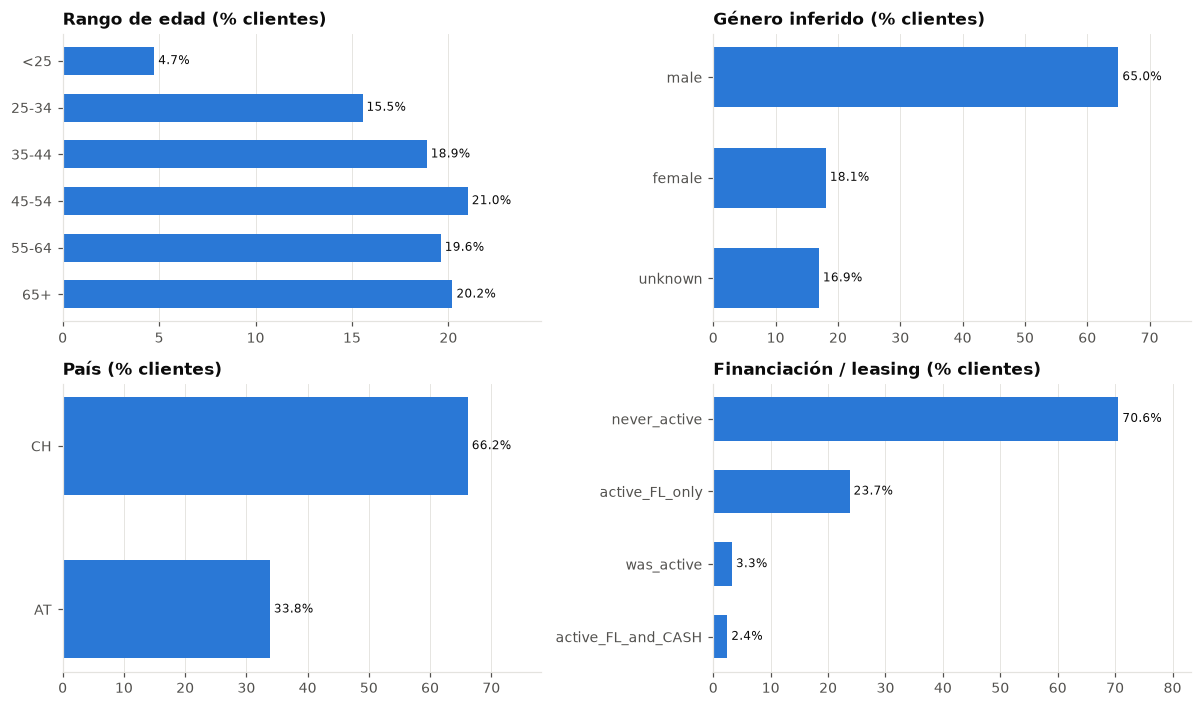

In [16]:
fig, axs = plt.subplots(2, 2, figsize=(11, 6.5))
order = config.AGE_ORDER
barh(cli.age_range.value_counts(normalize=True).reindex(order) * 100, 'Rango de edad (% clientes)', '{:.1f}%', ax=axs[0, 0])
barh(cli.gender.fillna('unknown').value_counts(normalize=True) * 100, 'Género inferido (% clientes)', '{:.1f}%', ax=axs[0, 1])
barh(cli.country.value_counts(normalize=True) * 100, 'País (% clientes)', '{:.1f}%', ax=axs[1, 0])
barh(cli.finance.value_counts(normalize=True) * 100, 'Financiación / leasing (% clientes)', '{:.1f}%', ax=axs[1, 1])
plt.tight_layout(); plt.savefig(FIG / '01_demografia.png'); plt.show()

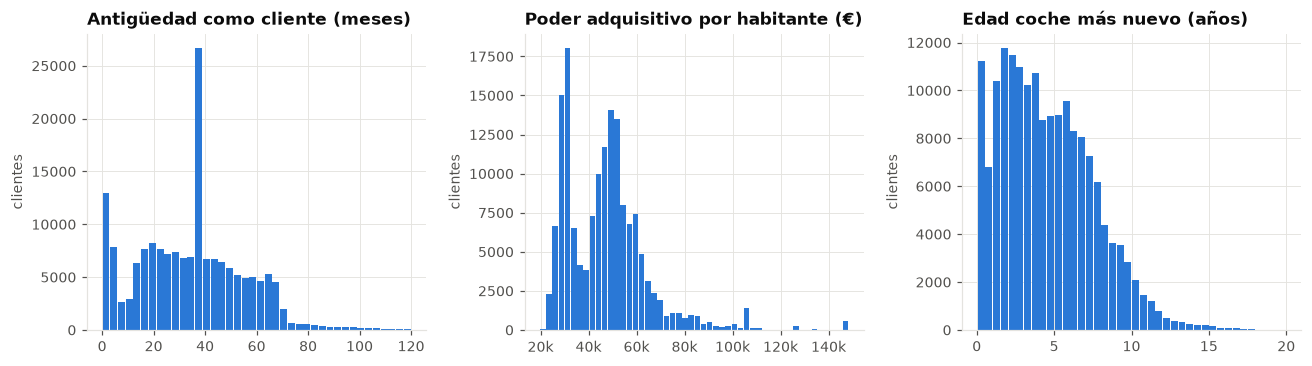

Mediana poder adquisitivo por habitante: {'AT': 30178.0, 'CH': 51434.0}


In [17]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
axs[0].hist(cli.tenure_months.dropna(), bins=40, color=BLUE, rwidth=.9); axs[0].set_title('Antigüedad como cliente (meses)', loc='left')
axs[1].hist(cli.pp_inhabitant.dropna(), bins=50, color=BLUE, rwidth=.9); axs[1].set_title('Poder adquisitivo por habitante (€)', loc='left')
axs[1].xaxis.set_major_formatter(mt.FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
axs[2].hist(cli.newest_vehicle_age.dropna().clip(upper=20), bins=40, color=BLUE, rwidth=.9); axs[2].set_title('Edad coche más nuevo (años)', loc='left')
for a in axs: a.set_ylabel('clientes')
plt.tight_layout(); plt.savefig(FIG / '01_numericas.png'); plt.show()
print('Mediana poder adquisitivo por habitante:', cli.groupby('country').pp_inhabitant.median().round(0).to_dict())

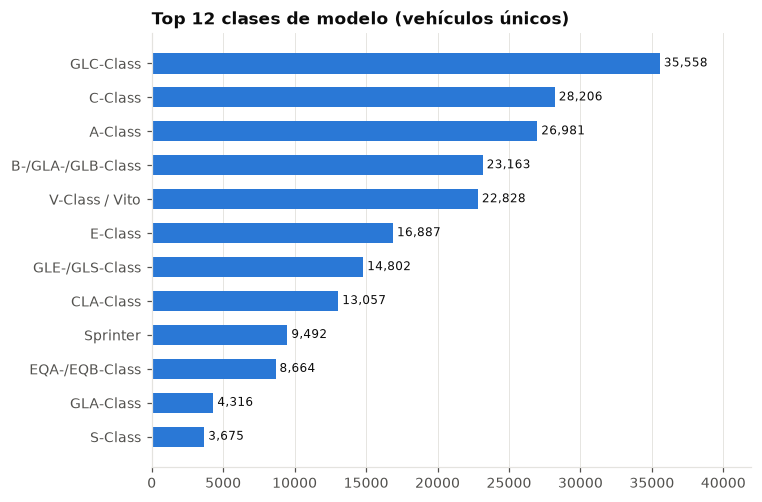

In [18]:
barh(df.drop_duplicates('vehicle_id').model_class.value_counts().head(12), 'Top 12 clases de modelo (vehículos únicos)')
plt.tight_layout(); plt.savefig(FIG / '01_modelos.png'); plt.show()

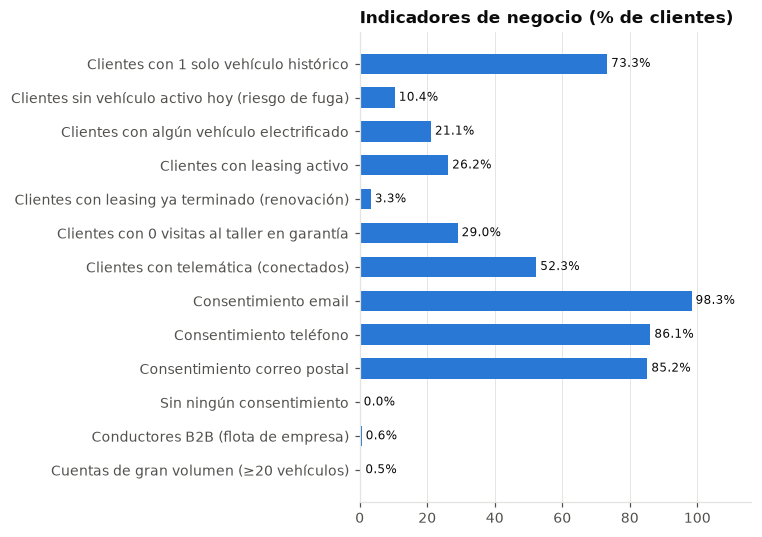

In [19]:
kpi = pd.Series({
    'Clientes con 1 solo vehículo histórico': (cli.n_vehicles_hist == 1).mean(),
    'Clientes sin vehículo activo hoy (riesgo de fuga)': (cli.n_vehicles_current == 0).mean(),
    'Clientes con algún vehículo electrificado': cli.any_electrified.mean(),
    'Clientes con leasing activo': cli.finance.str.startswith('active').mean(),
    'Clientes con leasing ya terminado (renovación)': cli.finance.eq('was_active').mean(),
    'Clientes con 0 visitas al taller en garantía': (cli.workshop_visits == 0).mean(),
    'Clientes con telemática (conectados)': cli.has_telemetry.mean(),
    'Consentimiento email': cli.consent_email.mean(), 'Consentimiento teléfono': cli.consent_phone.mean(),
    'Consentimiento correo postal': cli.consent_post.mean(), 'Sin ningún consentimiento': (cli.n_consents == 0).mean(),
    'Conductores B2B (flota de empresa)': cli.is_b2b_driver.mean(),
    'Cuentas de gran volumen (≥20 vehículos)': cli.is_heavy_account.mean()}) * 100
barh(kpi.round(1), 'Indicadores de negocio (% de clientes)', '{:.1f}%')
plt.tight_layout(); plt.savefig(FIG / '01_kpis_negocio.png'); plt.show()

In [20]:
# Cruces con lectura de marketing directa
display((pd.crosstab(cli.age_range, cli.any_electrified, normalize='index')[True] * 100).reindex(order).round(1).to_frame('% con electrificado'))
display((pd.crosstab(cli.age_range, cli.finance, normalize='index') * 100).reindex(order).round(1))
display(cli.groupby('country')[['any_electrified', 'has_telemetry', 'consent_phone', 'consent_post']].mean().mul(100).round(1))

,% con electrificado
age_range,
<25,11.5
25-34,14.2
35-44,19.8
45-54,23.8
55-64,25.4
65+,23.2


finance,active_FL_and_CASH,active_FL_only,never_active,was_active
age_range,,,,
<25,1.7,20.5,75.4,2.4
25-34,2.2,26.5,67.0,4.4
35-44,3.0,29.8,63.3,3.9
45-54,3.2,27.8,65.7,3.3
55-64,2.9,23.8,70.6,2.8
65+,1.2,12.4,84.0,2.4


,any_electrified,has_telemetry,consent_phone,consent_post
country,,,,
AT,29.3,56.8,84.9,85.8
CH,17.0,50.0,86.7,85.0


## 6. Resumen de hallazgos y conclusiones
*Cifras a nivel cliente (173.456 clientes), extraídas de las salidas anteriores.*

### ¿Cuáles son las principales características de los clientes?
| Dimensión | Dato | Lectura para marketing |
|---|---|---|
| **Mercado** | 66 % Suiza, 34 % Austria. Poder adquisitivo mediano por habitante: **51k € (CH) frente a 30k € (AT)** | Dos mercados con niveles económicos muy distintos. **Ofertas, precios y gama se calibran por país** |
| **Edad** | Base madura: **61 % tiene 45+ años** y el 20 % tiene 65+. Solo un 4,7 % tiene menos de 25 | La fidelización del cliente sénior es prioritaria. El cliente joven es un nicho de **captación** (gama compacta, renting) |
| **Género (inferido)** | 65 % hombres, 18 % mujeres, **17 % desconocido** | Dato inferido y con huecos: útil para describir, **no para dirigir campañas** |
| **Vehículos** | **73 % tiene un solo coche** en su histórico. Un 0,5 % son cuentas de ≥20 vehículos | La mayoría compra un coche cada vez, así que el **ciclo de recompra** es la palanca principal. Las flotas van por otro canal |
| **Gama** | Dominan los SUV (**GLC**, GLA/GLB, GLE/GLS) y C/A-Class. Hay un bloque relevante de **comerciales** (Vito/V-Class, Sprinter, Citan) | Cliente particular SUV frente a cliente profesional de furgoneta: necesidades y mensajes distintos |
| **Electrificación** | **21 %** tiene algún eléctrico o PHEV. **Crece con la edad**: 11,5 % en <25 frente a 25 % en 55-64. **AT 29 % frente a CH 17 %** | Contraintuitivo: el early adopter de EQ es **maduro y de alto valor**, no joven. Suiza tiene recorrido para campañas de transición |
| **Financiación** | 26 % con leasing activo (pico en 35-44 años); 3,3 % con leasing ya terminado | Los leasing terminados son una **ventana de renovación** concreta. Los mayores de 65 compran casi siempre al contado |
| **Actividad** | **10,4 % sin ningún vehículo activo** hoy | Clientes en **riesgo de fuga o reconquista** |
| **Taller** | 29 % sin visitas en garantía | Público objetivo de **planes de mantenimiento** y recordatorios de servicio |
| **Conectividad** | 52 % con telemática | Mitad digital/conectada: mantenimiento predictivo según uso real |
| **Consentimientos** | Email 98 %, teléfono 86 %, correo postal 85 %. Prácticamente nadie sin ningún canal | El **email es el canal universal**. El canal no restringe la segmentación, así que no conviene usarlo como feature principal |

### ¿Qué problemas de calidad hemos encontrado y cómo los resolvemos?
| Problema | Resolución |
|---|---|
| Granularidad mixta (cliente / vehículo / relación) | Agregar a **una fila por cliente** |
| Cuentas de gran volumen que distorsionan | Flag `is_heavy_account` y segmento aparte |
| Telemática ausente en ~48 % de los clientes (estructural) | Flag `has_telemetry` + ablación D3; la evidencia favorece no usarla en el modelo base |
| Motor y combustible nulos (44 % / 59 %) | Hoy: EQ → `ELECTRIC`, resto `UNKNOWN`. Propuesta: imputar desde `vehicle_type` (~99 % pureza, recupera el 54 %). Excluir `fuel_type` |
| Socioeconómicos nulos (6 %), `population == 0`, CP inválidos | Mediana por país + flag |
| Género inferido nulo (11 %) | Categoría `unknown`, no imputar |
| Redundancias (`role_type`, `fuel_type`, poder adquisitivo ×3, `connected_vehicles`) | Conservar una sola variable por concepto |
| Columnas `*_mode` con listas y valores en bins | Excluir |
| Extremos físicamente dudosos | Winsorizar p1-p99 / log en colas largas |
| Antigüedad = 36 meses en el 12 % (valor por defecto de carga) | Flag `tenure_is_default`; antigüedad alternativa desde la matriculación |
| `connected_vehicles` incoherente en 4 clientes | Recalcular desde `is_current_vehicle` |

**Siguiente paso (Reto 2):** llevar estas decisiones al `Pipeline` sobre la tabla de clientes (`clients.pkl`). Hay dos propuestas que afectan a `src/clean.py` (imputación de motor por `vehicle_type` y flag `tenure_is_default`); se aplican con el visto bueno de su dueño.